In [2]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
!unzip "/content/drive/MyDrive/lise makale/200X_CNN_data.zip"

In [8]:
dataname= "200X_Data"
adenosis = glob("/content/"+dataname+"_CNN_DATA/train/adenosis/*.png")
print("train adenosis",len(adenosis))

fibroadenoma = glob("/content/"+dataname+"_CNN_DATA/train/fibroadenoma/*.png")
print("train fibroadenoma",len(fibroadenoma))


phyllodes_tumor = glob("/content/"+dataname+"_CNN_DATA/train/phyllodes_tumor/*.png")
print("train phyllodes_tumor",len(phyllodes_tumor))


tubular_adenoma = glob("/content/"+dataname+"_CNN_DATA/train/tubular_adenoma/*.png")
print("train tubular_adenoma",len(tubular_adenoma))


ductal_carcinoma = glob("/content/"+dataname+"_CNN_DATA/train/ductal_carcinoma/*.png")
print("train ductal_carcinoma",len(ductal_carcinoma))


lobular_carcinoma = glob("/content/"+dataname+"_CNN_DATA/train/lobular_carcinoma/*.png")
print("train lobular_carcinoma",len(lobular_carcinoma))


mucinous_carcinoma = glob("/content/"+dataname+"_CNN_DATA/train/mucinous_carcinoma/*.png")
print("train mucinous_carcinoma",len(mucinous_carcinoma))


papillary_carcinoma = glob("/content/"+dataname+"_CNN_DATA/train/papillary_carcinoma/*.png")
print("train papillary_carcinoma",len(papillary_carcinoma))


print("-----------")

adenosis = glob("/content/"+dataname+"_CNN_DATA/test/adenosis/*.png")
print("test adenosis",len(adenosis))

fibroadenoma = glob("/content/"+dataname+"_CNN_DATA/test/fibroadenoma/*.png")
print("test fibroadenoma",len(fibroadenoma))


phyllodes_tumor = glob("/content/"+dataname+"_CNN_DATA/test/phyllodes_tumor/*.png")
print("test phyllodes_tumor",len(phyllodes_tumor))


tubular_adenoma = glob("/content/"+dataname+"_CNN_DATA/test/tubular_adenoma/*.png")
print("test tubular_adenoma",len(tubular_adenoma))


ductal_carcinoma = glob("/content/"+dataname+"_CNN_DATA/test/ductal_carcinoma/*.png")
print("test ductal_carcinoma",len(ductal_carcinoma))


lobular_carcinoma = glob("/content/"+dataname+"_CNN_DATA/test/lobular_carcinoma/*.png")
print("test lobular_carcinoma",len(lobular_carcinoma))


mucinous_carcinoma = glob("/content/"+dataname+"_CNN_DATA/test/mucinous_carcinoma/*.png")
print("test mucinous_carcinoma",len(mucinous_carcinoma))


papillary_carcinoma = glob("/content/"+dataname+"_CNN_DATA/test/papillary_carcinoma/*.png")
print("test papillary_carcinoma",len(papillary_carcinoma))




train adenosis 77
train fibroadenoma 184
train phyllodes_tumor 75
train tubular_adenoma 98
train ductal_carcinoma 140
train lobular_carcinoma 114
train mucinous_carcinoma 137
train papillary_carcinoma 94
-----------
test adenosis 34
test fibroadenoma 80
test phyllodes_tumor 33
test tubular_adenoma 42
test ductal_carcinoma 60
test lobular_carcinoma 49
test mucinous_carcinoma 59
test papillary_carcinoma 41


In [5]:
from glob import  glob
import os
import shutil
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd
import os
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import warnings
import matplotlib.pyplot as plt
from sklearn import model_selection
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix

import cv2
import random


In [19]:
from keras.preprocessing.image import ImageDataGenerator
from keras.callbacks import ReduceLROnPlateau
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPool2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.optimizers import RMSprop
from keras import regularizers
from keras.layers.core import Dropout
from keras.applications.vgg16 import VGG16
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.losses import categorical_crossentropy
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.losses import BinaryCrossentropy
from tensorflow.keras.applications import Xception
from sklearn.metrics import precision_score, f1_score, recall_score, accuracy_score, roc_auc_score
from tensorflow.keras.layers import Dense, Activation, Dropout, Flatten, GlobalAveragePooling2D, BatchNormalization, ZeroPadding2D
from keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau


In [9]:
train = '/content/200X_Data_CNN_DATA/train'
test =  '/content/200X_Data_CNN_DATA/test'

classes = ["adenosis","fibroadenoma","papillary_carcinoma","tubular_adenoma","ductal_carcinoma","lobular_carcinoma","mucinous_carcinoma","papillary_carcinoma"]

In [26]:
train_data = ImageDataGenerator(rescale=1./255,
                                   zoom_range=0.3,validation_split=0.15,
                                   horizontal_flip=True)
test_data = ImageDataGenerator(rescale=1./255)



traindata = train_data.flow_from_directory(train,
                                                batch_size=8,subset = "training",
                                                target_size=(224,224),
                                                shuffle=True,
                                                color_mode='rgb',
                                                class_mode='categorical')

validationdata = train_data.flow_from_directory(train,
                                                batch_size=8,
                                                target_size=(224,224),subset = "validation",
                                                shuffle=True,
                                                color_mode='rgb',
                                                class_mode='categorical')

testdata = test_data.flow_from_directory(test,
                                                batch_size=8,
                                                target_size=(224,224),
                                                shuffle=False,
                                                color_mode='rgb',
                                                class_mode='categorical')
train_size = len(traindata.filenames)
validation_size = len(validationdata.filenames)


Found 784 images belonging to 8 classes.
Found 135 images belonging to 8 classes.
Found 398 images belonging to 8 classes.
train_size 784
validation_size 135


In [ ]:
batch_size = 16
Xceptionmodel = Xception(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

x = Dropout(.1)(Xceptionmodel.output)
x = GlobalAveragePooling2D()(x)
#x = GlobalAveragePooling2D()(res.output)
#x = Flatten()(x)
#x = Dropout(.2)(x)
#x = Dense(units=2056, activation='relu')(x)
#x = Dense(units=1028, activation='relu')(x)
output = Dense(units=8, activation='softmax')(x)
#output = Dense(units=5, activation='sigmoid')(x)
Xceptionmodel = Model(inputs=Xceptionmodel.input, outputs=output)


for layer in Xceptionmodel.layers[:]:
    layer.trainable = False

for layer in Xceptionmodel.layers[-20:]:
    layer.trainable = True

for i, layer in enumerate(Xceptionmodel.layers): print(i, layer.name, layer.trainable)

Xceptionmodel.compile(optimizer=Adam(learning_rate=0.01), loss='categorical_crossentropy', metrics=['accuracy'])

es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=22)

Xceptionmodel.summary()


In [36]:
checkpoint_filepath = "./check_pointaccyeni"
model_checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_filepath,
    save_weights_only=False,
    monitor='val_accuracy',
    mode='max',
    save_best_only=True)

checkpoint_filepath = "./check_pointlosyeni"
model_checkpoint_callback_loss = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_filepath,
    save_weights_only=False,
    monitor='val_loss',
    mode='min',
    save_best_only=True)

reduce_lr = ReduceLROnPlateau(monitor='val_loss',
                              factor=0.2,
                              patience=5,
                              verbose=2,
                              min_delta=0.0001)

In [37]:
history = Xceptionmodel.fit(traindata,
                    steps_per_epoch=(train_size//batch_size),
                    validation_data=validationdata,
                    validation_steps=(validation_size//batch_size),
                    epochs= 100 ,
                    callbacks=[model_checkpoint_callback, model_checkpoint_callback_loss, reduce_lr, es],
                    verbose=1
                    )


Epoch 1/100
49/49 [==============================] - ETA: 0s - loss: 2.1838 - accuracy: 0.2500

49/49 [==============================] - 57s 1s/step - loss: 2.1838 - accuracy: 0.2500 - val_loss: 23.5117 - val_accuracy: 0.1719 - lr: 0.0100
Epoch 2/100
49/49 [==============================] - ETA: 0s - loss: 1.8972 - accuracy: 0.2857

49/49 [==============================] - 29s 595ms/step - loss: 1.8972 - accuracy: 0.2857 - val_loss: 50.1620 - val_accuracy: 0.2500 - lr: 0.0100
Epoch 3/100
49/49 [==============================] - ETA: 0s - loss: 1.6710 - accuracy: 0.3673

49/49 [==============================] - 28s 576ms/step - loss: 1.6710 - accuracy: 0.3673 - val_loss: 5.9715 - val_accuracy: 0.1875 - lr: 0.0100
Epoch 4/100
49/49 [==============================] - 12s 234ms/step - loss: 1.6326 - accuracy: 0.4107 - val_loss: 6.0937 - val_accuracy: 0.1719 - lr: 0.0100
Epoch 5/100
49/49 [==============================] - ETA: 0s - loss: 1.5408 - accuracy: 0.4439

49/49 [==============================] - 30s 610ms/step - loss: 1.5408 - accuracy: 0.4439 - val_loss: 6.2369 - val_accuracy: 0.3125 - lr: 0.0100
Epoch 6/100
49/49 [==============================] - ETA: 0s - loss: 1.4672 - accuracy: 0.4158

...

49/49 [==============================] - 29s 601ms/step - loss: 1.0482 - accuracy: 0.6276 - val_loss: 2.7972 - val_accuracy: 0.2656 - lr: 0.0020
Epoch 14/100
49/49 [==============================] - ETA: 0s - loss: 0.9417 - accuracy: 0.6480

49/49 [==============================] - 44s 903ms/step - loss: 0.9417 - accuracy: 0.6480 - val_loss: 2.3762 - val_accuracy: 0.4062 - lr: 0.0020
Epoch 15/100
49/49 [==============================] - 13s 267ms/step - loss: 0.8592 - accuracy: 0.6709 - val_loss: 2.4010 - val_accuracy: 0.3125 - lr: 0.0020
Epoch 16/100
49/49 [==============================] - ETA: 0s - loss: 0.9235 - accuracy: 0.6658

49/49 [==============================] - 28s 588ms/step - loss: 0.9235 - accuracy: 0.6658 - val_loss: 2.2691 - val_accuracy: 0.4062 - lr: 0.0020
Epoch 17/100
49/49 [==============================] - ETA: 0s - loss: 0.8556 - accuracy: 0.6709

49/49 [==============================] - 29s 595ms/step - loss: 0.8556 - accuracy: 0.6709 - val_loss: 2.4326 - val_accuracy: 0.4531 - lr: 0.0020
Epoch 18/100
49/49 [==============================] - 13s 268ms/step - loss: 0.8195 - accuracy: 0.7015 - val_loss: 2.3005 - val_accuracy: 0.4062 - lr: 0.0020
Epoch 19/100
49/49 [==============================] - ETA: 0s - loss: 0.7715 - accuracy: 0.7219

49/49 [==============================] - 30s 616ms/step - loss: 0.5742 - accuracy: 0.7832 - val_loss: 1.9941 - val_accuracy: 0.4844 - lr: 1.6000e-05
Epoch 36/100
49/49 [==============================] - 13s 272ms/step - loss: 0.5378 - accuracy: 0.8036 - val_loss: 2.5257 - val_accuracy: 0.3438 - lr: 1.6000e-05
Epoch 37/100
49/49 [==============================] - ETA: 0s - loss: 0.5519 - accuracy: 0.7934

In [38]:
score_val_model = Xceptionmodel.evaluate(validationdata, steps = len(validationdata), verbose = 0)
print('val loss:', score_val_model[0])
print('val accuracy:', score_val_model[1])


val loss: 2.5359749794006348
val accuracy: 0.4148148000240326


In [39]:
score_test_model = Xceptionmodel.evaluate(testdata, steps = len(testdata), verbose = 0)
print('Test loss:', score_test_model[0])
print('Test accuracy:', score_test_model[1])


Test loss: 1.1253385543823242
Test accuracy: 0.6834170818328857


In [40]:
import keras
# Calling `save('my_model')` creates a SavedModel folder `my_model`.
Xceptionmodel.save("/content/drive/MyDrive/lise makale/Xceptionmodel/train 2/Xceptionmodel.h5")


In [41]:
Xceptionmodel = keras.models.load_model('/content/drive/MyDrive/lise makale/Xceptionmodel/train 2/Xceptionmodel.h5')

In [42]:
preds_Xceptionmodel = Xceptionmodel.predict(testdata,steps=len(testdata))

50/50 [==============================] - 12s 188ms/step


In [ ]:
import json,codecs
with open("history.json","w") as f:
    json.dump(history.history,f)
with codecs.open("history.json","r",encoding="utf-8") as f:
    n = json.loads(f.read())

In [ ]:
plt.plot(n["loss"],label = "training loss")
plt.plot(n["val_loss"],label = "validation loss")
plt.savefig('LOSS.png')
plt.legend()
plt.show()


plt.plot(n["accuracy"],label = "training acc")
plt.plot(n["val_accuracy"],label = "validation acc")
plt.savefig('accuracy.png')
plt.legend()
plt.show()



In [ ]:
shutil.copy("/content/LOSS.png","/content/drive/MyDrive/lise makale/Xceptionmodel/train 2")
shutil.copy("/content/accuracy.png","/content/drive/MyDrive/lise makale/Xceptionmodel/train 2")

50/50 [==============================] - 6s 117ms/step


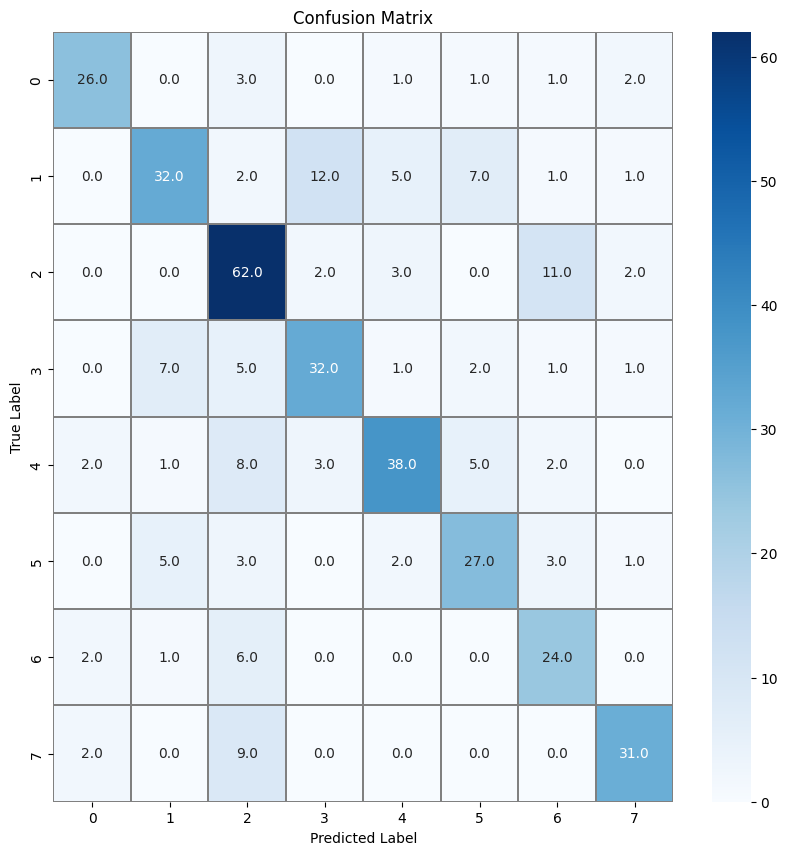

In [48]:
from sklearn.metrics import confusion_matrix
import seaborn as sns


Y_pred = Xceptionmodel.predict(testdata)
y_pred = np.argmax(Y_pred, axis=1)

confusion_mtx = confusion_matrix(testdata.classes, y_pred)
f,ax = plt.subplots(figsize=(10, 10))

sns.heatmap(confusion_mtx, annot=True, linewidths=0.01,cmap="Blues",linecolor="gray", fmt= '.1f',ax=ax)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.savefig('Confusion Matrix.png')

plt.show()

In [50]:
shutil.copy("/content/Confusion Matrix.png","/content/drive/MyDrive/lise makale/Xceptionmodel/train 2")

'/content/drive/MyDrive/lise makale/Xceptionmodel/train 2/Confusion Matrix.png'

In [49]:
print("Micro Precision: %f "%precision_score(testdata.classes, y_pred, average='micro'))
print("Micro Recall: %f "%recall_score(testdata.classes, y_pred, average='micro'))
print("Micro F1: %f"% f1_score(testdata.classes, y_pred, average='micro'))
#print("AUC Score: %f"%roc_auc_score(y_true, y_pred, average='micro'))
print("\n")

print("Acuracy: %f "%accuracy_score(testdata.classes, y_pred))
print("Macro Precision: %f "%precision_score(testdata.classes, y_pred, average='macro'))
print("Macro Recall: %f "%recall_score(testdata.classes, y_pred, average='macro'))
print("Macro F1: %f"% f1_score(testdata.classes, y_pred, average='macro'))
#print("AUC Score: %f"%roc_auc_score(testdata.classes, y_pred, average='macro'))
print("\n")

print("Weighted Precision: %f "%precision_score(testdata.classes, y_pred, average='weighted'))
print("Weighted Recall: %f "%recall_score(testdata.classes, y_pred, average='weighted'))
print("Weighted F1: %f"% f1_score(testdata.classes, y_pred, average='weighted'))
#print("ROC_AUC Score: %f"%roc_auc_score(testdata.classes, y_pred, average='weighted'))

Micro Precision: 0.683417 
Micro Recall: 0.683417 
Micro F1: 0.683417


Acuracy: 0.683417 
Macro Precision: 0.696332 
Macro Recall: 0.686759 
Macro F1: 0.686971


Weighted Precision: 0.693104 
Weighted Recall: 0.683417 
Weighted F1: 0.683289
